# CMMD Vanilla Model Training

In [ ]:
# @@ENV@@ — Keras backend, visible GPU and global seed
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

2026-10-06 21:57:05.741107: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791316625.754478 1246682 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791316625.758424 1246682 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists())
DATA_PATH = ROOT / 'data'  / 'cmmd' / 'processed'
ART_PATH = ROOT / 'artifacts' / 'cmmd'
sys.path.insert(0, str(ROOT))

In [6]:
import os
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
os.environ["KERAS_BACKEND"] = "tensorflow" # other options: tensorflow or torch

import keras_cv
import keras
import tensorflow as tf
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasCV:", keras_cv.__version__)

TensorFlow: 2.18.1
Keras: 3.15.0
KerasCV: 0.9.0


In [ ]:
# @@CFG@@ — every knob of the training run in one place
class CFG:
    verbose = 2  # Verbosity
    seed = 55  # Random seed
    neg_sample = 1.0 # Downsample negative train set class
    pos_sample = 1.0  # Upsample positive train set class
    val_neg_sample = 1.0
    val_pos_sample = 1.0 
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = (256, 256)  # Input image size
    epochs = 8 # Training epochs
    batch_size = 64  # Batch size
    shuffle_buffer = 1024
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1
    opt = keras.optimizers.Adam() # LR scheduler owns the rate, set from epoch 0
    loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

keras.utils.set_random_seed(CFG.seed)

I0000 00:00:1791317100.159093 1246682 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22800 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5


# 📖 | Meta Data


In [8]:
# Train + Valid
df = pd.read_parquet(f'{DATA_PATH}/train-metadata.parquet')
display(df.head(3))

# Testing
testing_df = pd.read_parquet(f'{DATA_PATH}/test-metadata.parquet')
display(testing_df.head(3))

,image_id,patient_id,target,age,abnormality,laterality,view,source_cohort,dicom_path
0,1.3.6.1.4.1.14519.5.2.1.1239.1759.171167992666...,D1-0001,0,44,calcification,R,CC,D1,The-Chinese-Mammography-Database/CMMD/D1-0001/...
1,1.3.6.1.4.1.14519.5.2.1.1239.1759.174844226756...,D1-0001,0,44,calcification,R,MLO,D1,The-Chinese-Mammography-Database/CMMD/D1-0001/...
2,1.3.6.1.4.1.14519.5.2.1.1239.1759.381899135082...,D1-0003,0,39,calcification,L,CC,D1,The-Chinese-Mammography-Database/CMMD/D1-0003/...


,image_id,patient_id,target,age,abnormality,laterality,view,source_cohort,dicom_path
0,1.3.6.1.4.1.14519.5.2.1.1239.1759.131904687741...,D1-0002,0,40,calcification,L,CC,D1,The-Chinese-Mammography-Database/CMMD/D1-0002/...
1,1.3.6.1.4.1.14519.5.2.1.1239.1759.586725248951...,D1-0002,0,40,calcification,L,MLO,D1,The-Chinese-Mammography-Database/CMMD/D1-0002/...
2,1.3.6.1.4.1.14519.5.2.1.1239.1759.474587943421...,D1-0005,0,42,calcification,R,CC,D1,The-Chinese-Mammography-Database/CMMD/D1-0005/...


In [12]:
# Tabular feature lists + cleaning/imputation helpers
NUMERIC_FEATURES = ["age"]
CATEGORICAL_FEATURES = ["view", "laterality"]

def clean_types(frame):
    frame = frame.copy()
    for c in NUMERIC_FEATURES:
        frame[c] = pd.to_numeric(frame[c], errors="coerce").astype("float32")
    for c in CATEGORICAL_FEATURES:
        frame[c] = frame[c].astype(str).replace(
            {"nan": "unknown", "None": "unknown", "": "unknown"})
    if "target" in frame:
        frame["target"] = frame["target"].astype("int32")
    return frame

def fit_imputation(frame):
    stats = {}
    for c in NUMERIC_FEATURES:
        stats[c] = float(pd.to_numeric(frame[c], errors="coerce").median())
    for c in CATEGORICAL_FEATURES:
        mode = frame[c].mode(dropna=True)
        stats[c] = mode.iloc[0] if len(mode) else "unknown"
    return stats

def apply_imputation(frame, stats):
    frame = frame.copy()
    for c in NUMERIC_FEATURES:
        frame[c] = pd.to_numeric(frame[c], errors="coerce").fillna(stats[c])
    for c in CATEGORICAL_FEATURES:
        frame[c] = frame[c].where(frame[c].notna(), stats[c]).astype(str)
    return frame

df = clean_types(df)
testing_df = clean_types(testing_df)

# ⚖️ | Handle Class Imbalance

In [13]:
print(df['target'].value_counts())

target
1    2100
0     886
Name: count, dtype: int64


# 🖼️ | Load Image Byte String


In [11]:
import h5py

training_validation_hdf5 = h5py.File(f"{ROOT}/data/cmmd/train-image.hdf5", 'r')
testing_hdf5 = h5py.File(f"{ROOT}/data/cmmd/test-image.hdf5", 'r')

Byte String: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x07z'....
Image:


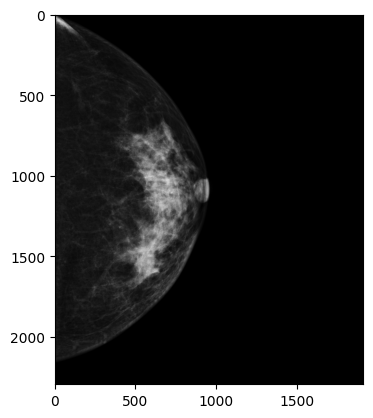

In [14]:
image_id = df.image_id.iloc[-10]

# Image as Byte String
byte_string = training_validation_hdf5[image_id][()]
print(f"Byte String: {byte_string[:20]}....")

# Convert byte string to numpy array
nparr = np.frombuffer(byte_string, np.uint8)

print("Image:")
image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1] # reverse last axis for bgr -> rgb
plt.imshow(image);

# 🔪 | Data Split

In [15]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
import json

df = df.reset_index(drop=True)
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.seed)
for i, (_, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

# Split first; validation stays at natural prevalence.
training_df = df.query("fold!=0").reset_index(drop=True)
validation_df = df.query("fold==0").reset_index(drop=True)
assert set(training_df.patient_id) & set(validation_df.patient_id) == set()

# Impute on training only, apply to both, persist for test.
impute_stats = fit_imputation(training_df)
training_df = apply_imputation(training_df, impute_stats)
validation_df = apply_imputation(validation_df, impute_stats)
feature_space_df = training_df.copy()

fs_dir = ART_PATH / "feature_space"
fs_dir.mkdir(parents=True, exist_ok=True)
with open(fs_dir / "impute_stats.json", "w") as f:
    json.dump(impute_stats, f)

# Class weights are estimated on the natural training distribution, before resampling.
class_weights = compute_class_weight("balanced", classes=np.unique(training_df.target), y=training_df.target)
class_weights = dict(enumerate(class_weights))

# Resample training only; validation and FeatureSpace adaptation remain natural.
neg = training_df.query("target==0").sample(frac=CFG.neg_sample, random_state=CFG.seed)
pos = training_df.query("target==1").sample(frac=CFG.pos_sample, replace=True, random_state=CFG.seed)
training_df = pd.concat([neg, pos]).sample(frac=1.0, random_state=CFG.seed).reset_index(drop=True)

print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)}")
print("Class Weights:", class_weights)


# Num Train: 2390 | Num Valid: 596
Class Weights: {0: np.float64(1.6830985915492958), 1: np.float64(0.7113095238095238)}


In [16]:
# class distribution in training and validation
print("training:", training_df.target.value_counts(),
      "\nvalidation:", validation_df.target.value_counts(), sep='\n')

training:
target
1    1680
0     710
Name: count, dtype: int64

validation:
target
1    420
0    176
Name: count, dtype: int64


## 📊 | Tabular Features

In [17]:
# Tabular feature columns: the lists the imputation was fitted on, and no second copy of them
FEAT_COLS = CATEGORICAL_FEATURES + NUMERIC_FEATURES

## 🍚 | DataLoader

In [18]:
# Build Training & Validation sets
from src.isic24.input_pipeline import build_dataset

print("# FeatureSpace adapt:")
feature_space_features = dict(feature_space_df[FEAT_COLS])
feature_space_ds = tf.data.Dataset.from_tensor_slices(feature_space_features).batch(CFG.batch_size)

print("# Training:")
training_features = dict(training_df[FEAT_COLS])
training_ids = training_df.image_id.values
training_labels = training_df.target.values
training_ds = build_dataset(training_ids, training_validation_hdf5, training_features,
                         training_labels, batch_size=CFG.batch_size,
                         shuffle=True, augment=True)

print("# Validation:")
validation_features = dict(validation_df[FEAT_COLS])
validation_ids = validation_df.image_id.values
validation_labels = validation_df.target.values
validation_ds = build_dataset(validation_ids, training_validation_hdf5, validation_features,
                         validation_labels, batch_size=CFG.batch_size,
                         shuffle=False, augment=False)



# FeatureSpace adapt:
# Training:
# Validation:


In [19]:
feature_space = keras.utils.FeatureSpace(
    features={**{c: "string_categorical" for c in CATEGORICAL_FEATURES},
              **{c: "float_normalized" for c in NUMERIC_FEATURES}},
    output_mode="concat",
)

## Adapt Tabular Features

In [20]:
feature_space.adapt(feature_space_ds)

In [21]:
fs_dir = ART_PATH / 'feature_space'

fs_dir.mkdir(parents=True, exist_ok=True)

feature_space.save(os.path.join(fs_dir, 'symile_feature_space.keras'))
print(f"FeatureSpace saved at: '{fs_dir}'")

FeatureSpace saved at: '/mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/feature_space'


In [22]:
# Apply Feature Processing
training_ds = training_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

validation_ds = validation_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

In [23]:
# loss & metric
auc = keras.metrics.AUC(name='auc')
loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

# 🤖 | Modeling

In [24]:
# Define input layers
image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
inp = {"images":image_input, "features":feat_input}

# Branch for image input
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
x1 = backbone(image_input)
x1 = keras.layers.GlobalAveragePooling2D()(x1)
x1 = keras.layers.Dropout(0.2)(x1)

# Branch for tabular/feature input
x2 = keras.layers.Dense(96, activation="selu")(feat_input)
x2 = keras.layers.Dense(128, activation="selu")(x2)
x2 = keras.layers.Dropout(0.1)(x2)

# Concatenate both branches
concat = keras.layers.Concatenate()([x1, x2])

# Output layer
out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

# Build model
model = keras.models.Model(inp, out)

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss,
    metrics=[auc],
)

# Model Summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer) │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features            │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficient_net_v2b2… │ (None, 8, 8,      │  8,769,374 │ images[0][0]      │
│ (EfficientNetV2Bac… │ 1408)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │        768 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1408)      │          0 │ efficient_net_v2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     12,416 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1408)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1536)      │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      1,537 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,784,095 (33.51 MB)

 Trainable params: 8,701,807 (33.19 MB)

 Non-trainable params: 82,288 (321.44 KB)

# ⚓ | LR Schedule

## Sanity Checks

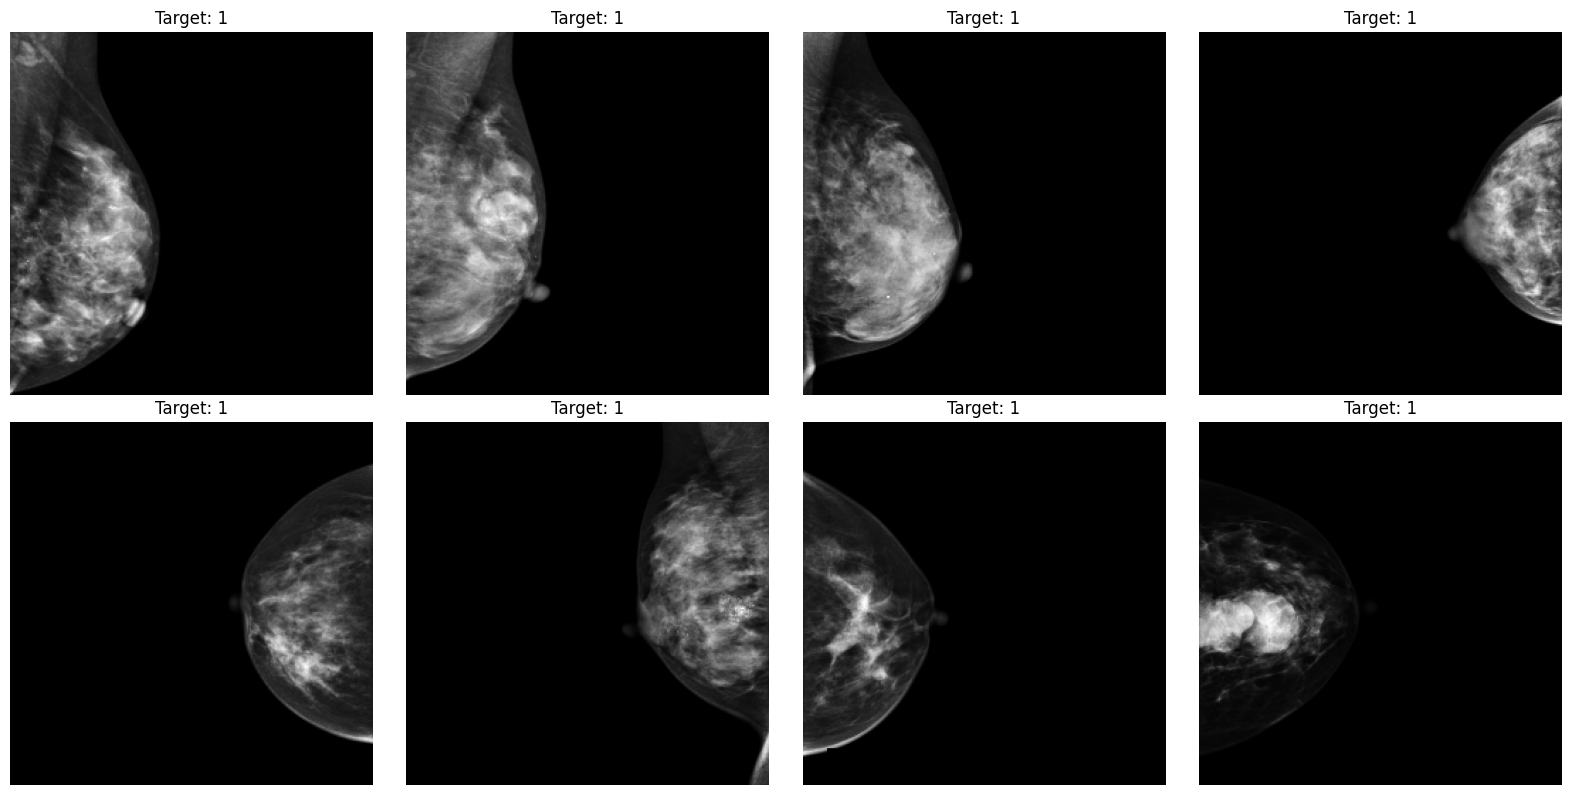

In [25]:
inputs, targets = next(iter(training_ds))
images = inputs["images"]
num_images, ncols = 8, 4

plt.figure(figsize=(4 * ncols, num_images // ncols * 4))
for i, (image, target) in enumerate(zip(images[:num_images], targets[:num_images])):
    plt.subplot(num_images // ncols, ncols, i + 1)
    image = image.numpy().astype("float32")
    target = target.numpy().astype("int32")[0]

    image = (image - image.min()) / (image.max() + 1e-4)

    plt.imshow(image)
    plt.title(f"Target: {target}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
import math
import matplotlib.pyplot as plt

def get_lr_callback(batch_size=8, mode='cos', epochs=20, plot=False):
    lr_start, lr_max, lr_min = 2.5e-5, 5e-6 * batch_size, 0.8e-5
    lr_ramp_ep, lr_sus_ep, lr_decay = 3, 0, 0.75

    def lrfn(epoch):  # Learning rate update function
        if epoch < lr_ramp_ep: lr = (lr_max - lr_start) / lr_ramp_ep * epoch + lr_start
        elif epoch < lr_ramp_ep + lr_sus_ep: lr = lr_max
        elif mode == 'exp': lr = (lr_max - lr_min) * lr_decay**(epoch - lr_ramp_ep - lr_sus_ep) + lr_min
        elif mode == 'step': lr = lr_max * lr_decay**((epoch - lr_ramp_ep - lr_sus_ep) // 2)
        elif mode == 'cos':
            decay_total_epochs, decay_epoch_index = epochs - lr_ramp_ep - lr_sus_ep + 3, epoch - lr_ramp_ep - lr_sus_ep
            phase = math.pi * decay_epoch_index / decay_total_epochs
            lr = (lr_max - lr_min) * 0.5 * (1 + math.cos(phase)) + lr_min
        return lr

    if plot:  # Plot lr curve if plot is True
        plt.figure(figsize=(10, 5))
        plt.plot(np.arange(epochs), [lrfn(epoch) for epoch in np.arange(epochs)], marker='o')
        plt.xlabel('epoch'); plt.ylabel('lr')
        plt.title('LR Scheduler')
        plt.show()

    return keras.callbacks.LearningRateScheduler(lrfn, verbose=False)  # Create lr callback

lr_cb = get_lr_callback(CFG.batch_size, mode=CFG.lr_mode, plot=False)

In [27]:
model_name = "symile_best_vanilla_model.keras"
MODEL_PATH = ART_PATH / 'vanilla'
model_filepath = os.path.join(MODEL_PATH, model_name)

ckpt_cb = keras.callbacks.ModelCheckpoint(
    model_filepath,   # Filepath where the model will be saved.
    monitor="val_auc",    # Metric to monitor (validation AUC in this case).
    save_best_only=True,  # Save only the model with the best performance.
    save_weights_only=False,  # Save the entire model (not just the weights).
    mode="max",           # The model with the maximum 'val_auc' will be saved.
)

# 🚂 | Training

In [28]:
history = model.fit(
    training_ds,
    epochs=CFG.epochs,
    callbacks=[lr_cb, ckpt_cb],
    validation_data=validation_ds,
    verbose=CFG.verbose,
    class_weight=class_weights,
)

Epoch 1/20


/home/cgiovannoni/miniconda3/envs/isic24_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791317687.981783 1249670 service.cc:148] XLA service 0x770098002e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791317687.981810 1249670 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
I0000 00:00:1791317694.561516 1249670 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1791317699.804609 1249670 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791317700.011953 1249670 gpu_timer.cc:82] Delay kernel

38/38 - 133s - 3s/step - auc: 0.4367 - loss: 0.7123 - val_auc: 0.4561 - val_loss: 0.6862 - learning_rate: 2.5000e-05
Epoch 2/20
38/38 - 11s - 294ms/step - auc: 0.6587 - loss: 0.6617 - val_auc: 0.6767 - val_loss: 0.6241 - learning_rate: 1.2333e-04
Epoch 3/20
38/38 - 11s - 293ms/step - auc: 0.7239 - loss: 0.6203 - val_auc: 0.7122 - val_loss: 0.6169 - learning_rate: 2.2167e-04
Epoch 4/20
38/38 - 11s - 297ms/step - auc: 0.7640 - loss: 0.5857 - val_auc: 0.7294 - val_loss: 0.5595 - learning_rate: 3.2000e-04
Epoch 5/20
38/38 - 10s - 260ms/step - auc: 0.8262 - loss: 0.5226 - val_auc: 0.7236 - val_loss: 0.5911 - learning_rate: 3.1808e-04
Epoch 6/20
38/38 - 11s - 297ms/step - auc: 0.8729 - loss: 0.4618 - val_auc: 0.7414 - val_loss: 0.6108 - learning_rate: 3.1236e-04
Epoch 7/20
38/38 - 10s - 259ms/step - auc: 0.9190 - loss: 0.3807 - val_auc: 0.7266 - val_loss: 0.6469 - learning_rate: 3.0300e-04
Epoch 8/20
38/38 - 10s - 260ms/step - auc: 0.9584 - loss: 0.2939 - val_auc: 0.7309 - val_loss: 0.7351 -

In [29]:
# save model
model.save(model_filepath, include_optimizer=True)
print(f"model saved at: {model_filepath}")

model saved at: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/vanilla/symile_best_vanilla_model.keras


## Visualize AUC with Epochs

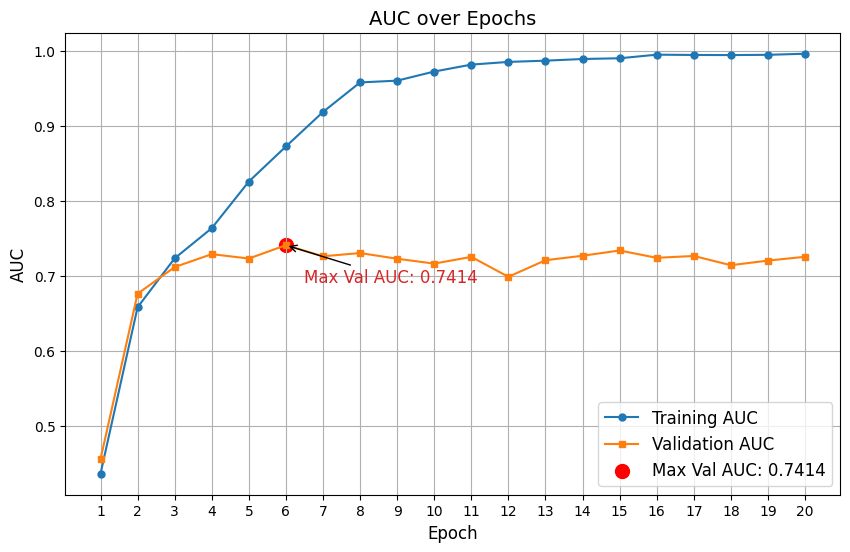

In [30]:
# Extract AUC and validation AUC from history
auc = history.history['auc']
val_auc = history.history['val_auc']
epochs = range(1, len(auc) + 1)

# Find the epoch with the maximum val_auc
max_val_auc_epoch = np.argmax(val_auc)
max_val_auc = val_auc[max_val_auc_epoch]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(epochs, auc, 'o-', label='Training AUC', markersize=5, color='tab:blue')
plt.plot(epochs, val_auc, 's-', label='Validation AUC', markersize=5, color='tab:orange')

# Highlight the max val_auc
plt.scatter(max_val_auc_epoch + 1, max_val_auc, color='red', s=100, label=f'Max Val AUC: {max_val_auc:.4f}')
plt.annotate(f'Max Val AUC: {max_val_auc:.4f}',
             xy=(max_val_auc_epoch + 1, max_val_auc),
             xytext=(max_val_auc_epoch + 1 + 0.5, max_val_auc - 0.05),
             arrowprops=dict(facecolor='black', arrowstyle="->"),
             fontsize=12,
             color='tab:red')

# Enhancing the plot
plt.title('AUC over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('AUC', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True)
plt.xticks(epochs)

# Show the plot
plt.show()

# 📋 | Result

In [31]:
# Best Result
best_score = max(history.history['val_auc'])
best_epoch = np.argmax(history.history['val_auc']) + 1
print("#" * 10 + " Result " + "#" * 10)
print(f"Best AUC: {best_score:.5f}")
print(f"Best Epoch: {best_epoch}")
print("#" * 28)

########## Result ##########
Best AUC: 0.74138
Best Epoch: 6
############################


# 🧪 | Prediction

In [32]:
model.load_weights(model_filepath)

In [33]:
# Build Testing Dataset
print("# Testing:")
import json
with open(ART_PATH / "feature_space" / "impute_stats.json") as f:
    impute_stats = json.load(f)
testing_df = apply_imputation(testing_df, impute_stats)

testing_features = dict(testing_df[FEAT_COLS])
testing_ids = testing_df.image_id.values
testing_ds = build_dataset(testing_ids, testing_hdf5,
                        testing_features, batch_size=CFG.batch_size,
                         shuffle=False, augment=False, cache=False)

# Apply feature space processing
testing_ds = testing_ds.map(
    lambda x: {"images": x["images"],
               "features": feature_space(x["features"])}, num_parallel_calls=tf.data.AUTOTUNE)

# Testing:


In [35]:
preds = model.predict(testing_ds).squeeze()

# set threshold
threshold = 0.5

# count positives
n_pos = np.sum(preds >= threshold)

print(f"Positive predictions: {n_pos}/{len(preds)}")
print(f"{100 * n_pos / len(preds):.2f}% positive predictions")


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step
Positive predictions: 452/748
60.43% positive predictions


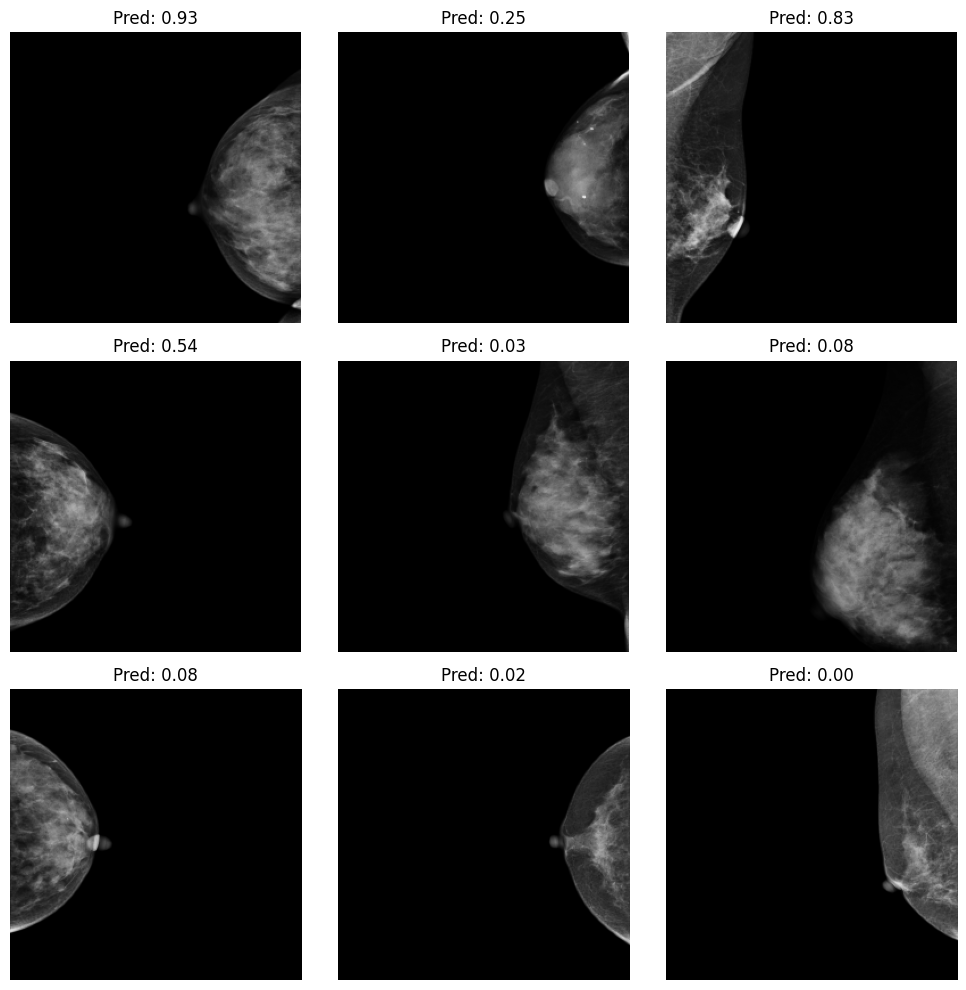

In [36]:
inputs = next(iter(testing_ds))
images = inputs["images"]

idxs = np.random.choice(len(images), size=9, replace=False)

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds[i]:.2f}')
    plt.axis('off')
plt.tight_layout(); plt.show()

E0000 00:00:1791318087.016870 1249673 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791318087.218141 1249673 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791318087.637036 1249673 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791318087.835118 1249673 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791318088.214537 1249673 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:0

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step


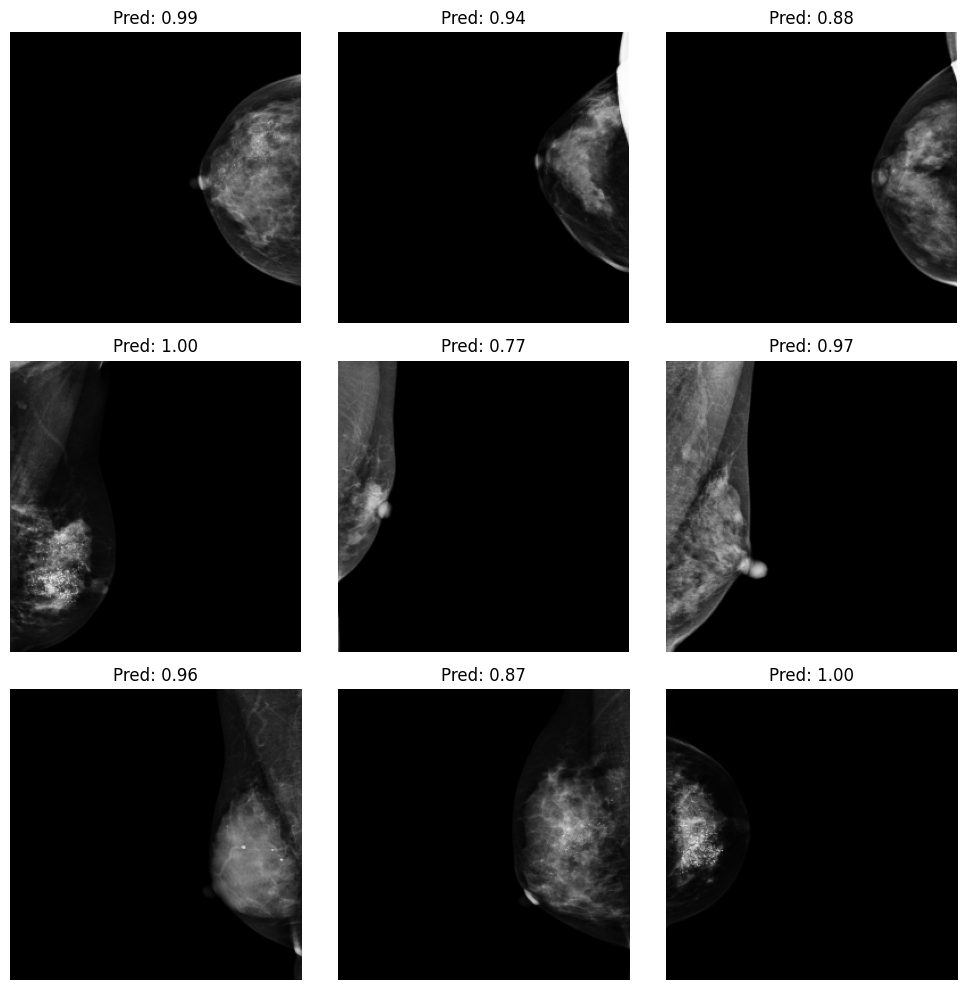

: 

In [ ]:
inputs = next(iter(testing_ds))
preds_batch = model.predict(inputs).squeeze()

images = inputs["images"]

pos_idxs = np.where(preds_batch >= 0.5)[0]

if len(pos_idxs) > 9:
    idxs = np.random.choice(pos_idxs, 9, replace=False)
else:
    idxs = pos_idxs

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds_batch[i]:.2f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# create a only positives predictions dataset
all_inputs = list(testing_ds.unbatch().as_numpy_iterator())
images = np.stack([x["images"] for x in all_inputs])
metadata = np.stack([x["metadata"] for x in all_inputs])

# predict
preds = model.predict({"images": images, "metadata": metadata}).squeeze()

# filter positives
pos_mask = preds >= 0.5
images_pos = images[pos_mask]
metadata_pos = metadata[pos_mask]

# rebuild dataset
positives_ds = tf.data.Dataset.from_tensor_slices({
    "images": images_pos,
    "metadata": metadata_pos
})